In [ ]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# read the data from the excel file
file_path = "/Users/rashithawerapitiya/Desktop/Retail Profitability Analysis/Data:Raw/sample_-_superstore.xls"

orders = pd.read_excel(file_path, sheet_name="Orders")
people = pd.read_excel(file_path, sheet_name="People")
returns = pd.read_excel(file_path, sheet_name="Returns")

In [ ]:
print("Orders:", orders.shape)
print("People:", people.shape)
print("Returns:", returns.shape)

orders.head()

Orders: (10194, 21)
People: (4, 2)
Returns: (296, 2)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  datetime64[ns]
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  object        
 6   Customer Name   10194 non-null  object        
 7   Segment         10194 non-null  object        
 8   Country/Region  10194 non-null  object        
 9   City            10194 non-null  object        
 10  State/Province  10194 non-null  object        
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  object        
 13  Product ID      10194 non-null  object        
 14  Category        10194 non-null  object        
 15  Su

In [ ]:
# check for missing values
orders.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [ ]:
# check for duplicate rows
orders.duplicated().sum()

np.int64(0)

In [ ]:
people.head()

,Regional Manager,Region
0,Sadie Pawthorne,West
1,Chuck Magee,East
2,Roxanne Rodriguez,Central
3,Fred Suzuki,South


In [ ]:
people.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Regional Manager  4 non-null      object
 1   Region            4 non-null      object
dtypes: object(2)
memory usage: 196.0+ bytes


In [ ]:
returns.head()

,Order ID,Returned
0,US-2023-100762,Yes
1,US-2023-100867,Yes
2,US-2023-102652,Yes
3,US-2023-103373,Yes
4,US-2023-103744,Yes


In [ ]:
returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Order ID  296 non-null    object
 1   Returned  296 non-null    object
dtypes: object(2)
memory usage: 4.8+ KB


In [ ]:
# check for unique values
returns["Order ID"].nunique()

296

In [ ]:
# merge the orders and returns dataframes to create a new dataframe with a "Returned" column
orders_clean = orders.merge(
    returns[["Order ID", "Returned"]],
    on="Order ID",
    how="left"
)

orders_clean["Returned"] = orders_clean["Returned"].fillna("No")

In [ ]:
orders_clean["Returned"].value_counts()

Returned
No     9394
Yes     800
Name: count, dtype: int64

In [ ]:
# create new columns for order year, month, month name, quarter, and month start
orders_clean["Order Year"] = orders_clean["Order Date"].dt.year
orders_clean["Order Month"] = orders_clean["Order Date"].dt.month
orders_clean["Order Month Name"] = orders_clean["Order Date"].dt.month_name()
orders_clean["Order Quarter"] = orders_clean["Order Date"].dt.quarter
orders_clean["Order Month Start"] = orders_clean["Order Date"].values.astype("datetime64[M]")

orders_clean["Shipping Days"] = (
    orders_clean["Ship Date"] - orders_clean["Order Date"]
).dt.days

In [ ]:
orders_clean[
    [
        "Order Date",
        "Order Year",
        "Order Month",
        "Order Month Name",
        "Order Quarter",
        "Order Month Start",
        "Ship Date",
        "Shipping Days",
    ]
].head()

,Order Date,Order Year,Order Month,Order Month Name,Order Quarter,Order Month Start,Ship Date,Shipping Days
0,2023-01-03,2023,1,January,1,2023-01-01,2023-01-07,4
1,2023-01-04,2023,1,January,1,2023-01-01,2023-01-08,4
2,2023-01-04,2023,1,January,1,2023-01-01,2023-01-08,4
3,2023-01-04,2023,1,January,1,2023-01-01,2023-01-08,4
4,2023-01-05,2023,1,January,1,2023-01-01,2023-01-12,7


In [ ]:
# create a new column for profit margin
orders_clean["Profit Margin"] = np.where(
    orders_clean["Sales"] != 0,
    orders_clean["Profit"] / orders_clean["Sales"],
    np.nan
)

# create a new column for discount band
orders_clean["Discount Band"] = pd.cut(
    orders_clean["Discount"],
    bins=[-0.01, 0, 0.10, 0.20, 1],
    labels=["No Discount", "Low (1–10%)", "Medium (11–20%)", "High (21%+)"]
)

In [ ]:
orders_clean[
    ["Sales", "Profit", "Profit Margin", "Discount", "Discount Band"]
].head(10)

,Sales,Profit,Profit Margin,Discount,Discount Band
0,16.448,5.5512,0.3375,0.2,Medium (11–20%)
1,3.540,-5.4870,-1.5500,0.8,High (21%+)
2,11.784,4.2717,0.3625,0.2,Medium (11–20%)
3,272.736,-64.7748,-0.2375,0.2,Medium (11–20%)
4,19.536,4.8840,0.2500,0.2,Medium (11–20%)
5,2573.820,746.4078,0.2900,0.0,No Discount
6,5.480,1.4796,0.2700,0.0,No Discount
7,12.780,5.2398,0.4100,0.0,No Discount
8,609.980,274.4910,0.4500,0.0,No Discount
9,31.120,0.3112,0.0100,0.0,No Discount


In [ ]:
orders_clean[
    [
        "Returned",
        "Order Year",
        "Order Month",
        "Order Quarter",
        "Order Month Start",
        "Profit Margin",
        "Discount Band",
    ]
].isnull().sum()

Returned             0
Order Year           0
Order Month          0
Order Quarter        0
Order Month Start    0
Profit Margin        0
Discount Band        0
dtype: int64

In [ ]:
orders_clean["Discount Band"].value_counts(dropna=False)

Discount Band
No Discount        4925
Medium (11–20%)    3758
High (21%+)        1415
Low (1–10%)          96
Name: count, dtype: int64

In [ ]:
# save the cleaned data to a new CSV file
from pathlib import Path

output_folder = Path("/Users/rashithawerapitiya/Desktop/Retail Profitability Analysis/Data:Cleaned")
output_folder.mkdir(parents=True, exist_ok=True)

orders_clean.to_csv(
    output_folder / "superstore_cleaned.csv",
    index=False
)

In [ ]:
# calculate key metrics
total_sales = orders_clean["Sales"].sum()
total_profit = orders_clean["Profit"].sum()
profit_margin = total_profit / total_sales
total_orders = orders_clean["Order ID"].nunique()
total_customers = orders_clean["Customer ID"].nunique()
average_order_value = total_sales / total_orders

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Profit Margin: {profit_margin:.2%}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")

Total Sales: $2,326,534.35
Total Profit: $292,296.81
Profit Margin: 12.56%
Total Orders: 5,111
Total Customers: 804
Average Order Value: $455.20


In [ ]:
# calculate monthly performance with total sales, total profit, total orders, and profit margin
monthly_performance = (
    orders_clean
    .groupby("Order Month Start", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
)

monthly_performance["Profit Margin"] = (
    monthly_performance["Total_Profit"]
    / monthly_performance["Total_Sales"]
)

monthly_performance.head()

,Order Month Start,Total_Sales,Total_Profit,Total_Orders,Profit Margin
0,2023-01-01,14518.055,2539.3907,33,0.174913
1,2023-02-01,4519.892,862.3084,28,0.190781
2,2023-03-01,56933.909,693.4499,72,0.012180
3,2023-04-01,28295.345,3488.8352,66,0.123301
4,2023-05-01,26319.767,3196.3918,72,0.121445


In [ ]:
# Monthly Highest Sales Performance (Top 5)
monthly_performance.sort_values(
    by="Total_Sales",
    ascending=False
).head(5)

,Order Month Start,Total_Sales,Total_Profit,Total_Orders,Profit Margin
46,2026-11-01,118454.5050,9692.1037,262,0.081821
35,2025-12-01,97502.2770,17926.3013,185,0.183855
44,2026-09-01,88064.5320,11050.8024,231,0.125485
47,2026-12-01,85175.0328,8655.8269,236,0.101624
45,2026-10-01,83474.7832,10670.5312,151,0.127829


In [ ]:
# Monthly Lowest Sales Performance (Bottom 5)
monthly_performance.sort_values(
    by="Total_Sales",
    ascending=True
).head(5)

,Order Month Start,Total_Sales,Total_Profit,Total_Orders,Profit Margin
1,2023-02-01,4519.8920,862.3084,28,0.190781
13,2024-02-01,11951.4110,2813.8508,36,0.235441
0,2023-01-01,14518.0550,2539.3907,33,0.174913
12,2024-01-01,18461.9156,-3189.8030,31,-0.172777
24,2025-01-01,18830.3310,2916.0233,50,0.154858


In [ ]:
# Monthly Highest Profit Performance (Top 5)
monthly_performance.sort_values(
    by="Total_Profit",
    ascending=False
).head(5)

,Order Month Start,Total_Sales,Total_Profit,Total_Orders,Profit Margin
35,2025-12-01,97502.2770,17926.3013,185,0.183855
33,2025-10-01,59831.0010,16256.8422,107,0.271713
38,2026-03-01,60728.4808,15013.0910,121,0.247217
22,2024-11-01,75972.5635,12474.7884,158,0.164201
44,2026-09-01,88064.5320,11050.8024,231,0.125485


In [ ]:
# Monthly Lowest Profit Performance (Bottom 5)
monthly_performance.sort_values(
    by="Total_Profit",
    ascending=True
).head(5)

,Order Month Start,Total_Sales,Total_Profit,Total_Orders,Profit Margin
12,2024-01-01,18461.9156,-3189.8030,31,-0.172777
6,2023-07-01,33946.3930,-841.4826,65,-0.024789
2,2023-03-01,56933.9090,693.4499,72,0.012180
1,2023-02-01,4519.8920,862.3084,28,0.190781
39,2026-04-01,36779.0361,957.5300,117,0.026035


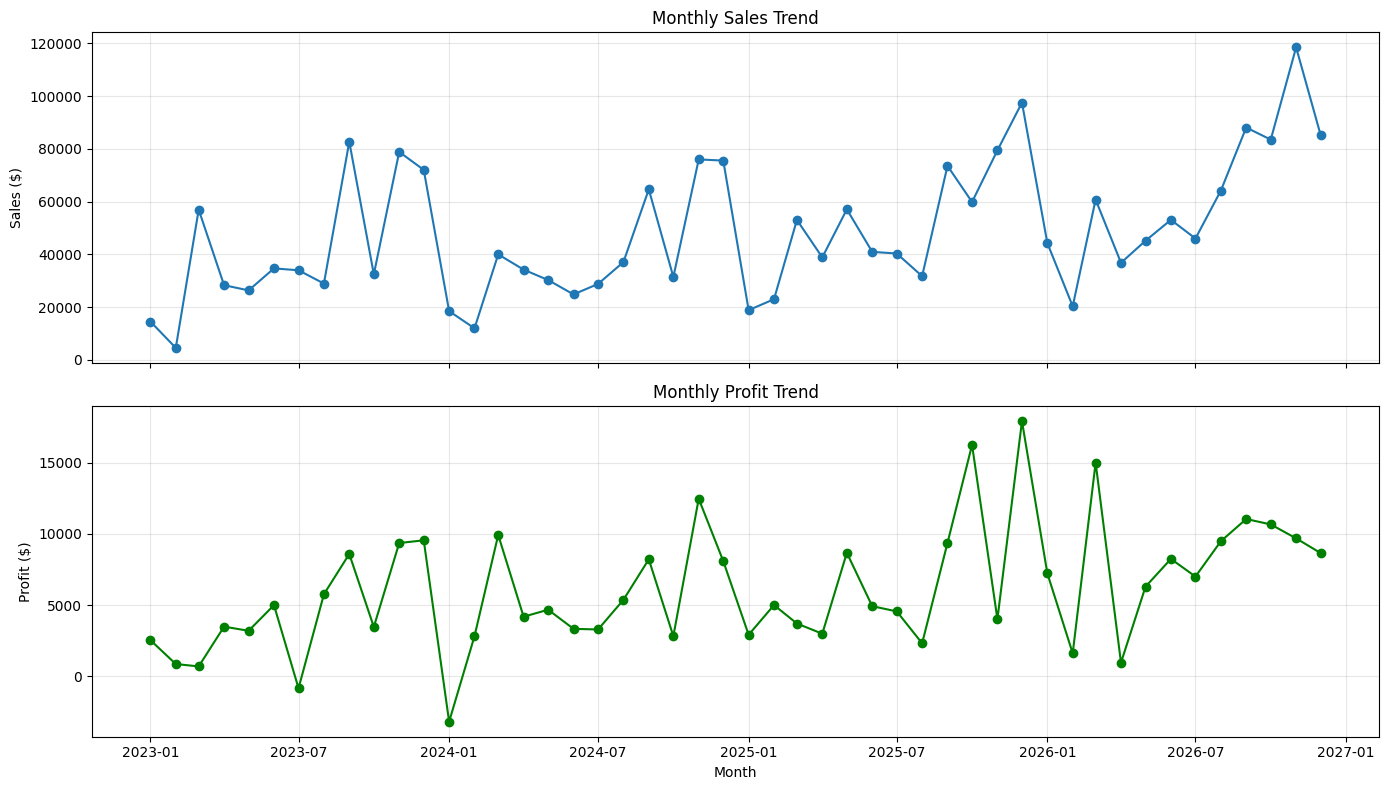

In [ ]:
# create line plots for monthly sales and profit trends
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(
    monthly_performance["Order Month Start"],
    monthly_performance["Total_Sales"],
    marker="o"
)
axes[0].set_title("Monthly Sales Trend")
axes[0].set_ylabel("Sales ($)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    monthly_performance["Order Month Start"],
    monthly_performance["Total_Profit"],
    marker="o",
    color="green"
)
axes[1].set_title("Monthly Profit Trend")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Profit ($)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Monthly Lowest Profit Margin Performance (Top 5)
monthly_performance.sort_values(
    by="Profit Margin",
    ascending=True
).head(5)

,Order Month Start,Total_Sales,Total_Profit,Total_Orders,Profit Margin
12,2024-01-01,18461.9156,-3189.8030,31,-0.172777
6,2023-07-01,33946.3930,-841.4826,65,-0.024789
2,2023-03-01,56933.9090,693.4499,72,0.012180
39,2026-04-01,36779.0361,957.5300,117,0.026035
34,2025-11-01,79411.9658,4011.4075,183,0.050514


In [ ]:
# calculate quarterly performance with total sales, total profit, total orders, and profit margin
quarterly_performance = (
    orders_clean
    .groupby(["Order Year", "Order Quarter"], as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
)

quarterly_performance["Profit Margin"] = (
    quarterly_performance["Total_Profit"]
    / quarterly_performance["Total_Sales"]
)

quarterly_performance

,Order Year,Order Quarter,Total_Sales,Total_Profit,Total_Orders,Profit Margin
0,2023,1,75971.8560,4095.1490,133,0.053904
1,2023,2,89284.5916,11684.9864,205,0.130873
2,2023,3,145535.1603,13517.3726,274,0.092880
3,2023,4,183248.6042,22386.7877,383,0.122166
4,2024,1,70391.9546,9554.6612,148,0.135735
5,2024,2,89239.4470,12200.1904,215,0.136713
6,2024,3,130449.3752,16880.3008,277,0.129401
7,2024,4,182912.2542,23385.8171,413,0.127853
8,2025,1,94840.2150,11628.4890,183,0.122611
9,2025,2,136809.1450,16594.6767,299,0.121298


In [ ]:
# Quarterly Highest Sales Performance (Top 5)
quarterly_performance.sort_values(
    by="Total_Sales",
    ascending=False
).head(5)

,Order Year,Order Quarter,Total_Sales,Total_Profit,Total_Orders,Profit Margin
15,2026,4,287104.3210,29018.4618,649,0.101073
11,2025,4,236745.2438,38194.5510,475,0.161332
14,2026,3,198183.7860,27545.3758,457,0.138989
3,2023,4,183248.6042,22386.7877,383,0.122166
7,2024,4,182912.2542,23385.8171,413,0.127853


In [ ]:
# Quarterly Lowest Sales Performance (Bottom 5)
quarterly_performance.sort_values(
    by="Total_Sales",
    ascending=True
).head(5)

,Order Year,Order Quarter,Total_Sales,Total_Profit,Total_Orders,Profit Margin
4,2024,1,70391.9546,9554.6612,148,0.135735
0,2023,1,75971.8560,4095.1490,133,0.053904
5,2024,2,89239.4470,12200.1904,215,0.136713
1,2023,2,89284.5916,11684.9864,205,0.130873
8,2025,1,94840.2150,11628.4890,183,0.122611


In [ ]:
# Quarterly Highest Profit (Top 5)
quarterly_performance.sort_values(
    by="Total_Profit",
    ascending=False
).head(5)

,Order Year,Order Quarter,Total_Sales,Total_Profit,Total_Orders,Profit Margin
11,2025,4,236745.2438,38194.5510,475,0.161332
15,2026,4,287104.3210,29018.4618,649,0.101073
14,2026,3,198183.7860,27545.3758,457,0.138989
12,2026,1,125288.8282,23858.6021,245,0.190429
7,2024,4,182912.2542,23385.8171,413,0.127853


In [ ]:
# Quarterly Lowest Profit (Bottom 5)
quarterly_performance.sort_values(
    by="Total_Profit",
    ascending=True
).head(5)

,Order Year,Order Quarter,Total_Sales,Total_Profit,Total_Orders,Profit Margin
0,2023,1,75971.8560,4095.1490,133,0.053904
4,2024,1,70391.9546,9554.6612,148,0.135735
8,2025,1,94840.2150,11628.4890,183,0.122611
1,2023,2,89284.5916,11684.9864,205,0.130873
5,2024,2,89239.4470,12200.1904,215,0.136713


In [ ]:
# Quarterly Highest Profit Margin (Top 5)
quarterly_performance.sort_values(
    by="Profit Margin",
    ascending=False
).head(5)

,Order Year,Order Quarter,Total_Sales,Total_Profit,Total_Orders,Profit Margin
12,2026,1,125288.8282,23858.6021,245,0.190429
11,2025,4,236745.2438,38194.5510,475,0.161332
14,2026,3,198183.7860,27545.3758,457,0.138989
5,2024,2,89239.4470,12200.1904,215,0.136713
4,2024,1,70391.9546,9554.6612,148,0.135735


In [ ]:
# Quarterly Lowest Profit Margin (Bottom 5)
quarterly_performance.sort_values(
    by="Profit Margin",
    ascending=True
).head(5)

,Order Year,Order Quarter,Total_Sales,Total_Profit,Total_Orders,Profit Margin
0,2023,1,75971.8560,4095.1490,133,0.053904
2,2023,3,145535.1603,13517.3726,274,0.092880
15,2026,4,287104.3210,29018.4618,649,0.101073
10,2025,3,145538.9762,16247.4851,383,0.111637
13,2026,2,134990.5960,15503.9079,372,0.114852


In [ ]:
# calculate sales and profit changes for each quarter
quarterly_performance["Sales Change"] = (
    quarterly_performance["Total_Sales"].diff()
)

quarterly_performance["Profit Change"] = (
    quarterly_performance["Total_Profit"].diff()
)

quarterly_performance["Sales Growth %"] = (
    quarterly_performance["Total_Sales"].pct_change()
)

quarterly_performance["Profit Growth %"] = (
    quarterly_performance["Total_Profit"].pct_change()
)

quarterly_performance

,Order Year,Order Quarter,Total_Sales,Total_Profit,Total_Orders,Profit Margin,Sales Change,Profit Change,Sales Growth %,Profit Growth %
0,2023,1,75971.8560,4095.1490,133,0.053904,NaN,NaN,NaN,NaN
1,2023,2,89284.5916,11684.9864,205,0.130873,13312.7356,7589.8374,0.175232,1.853373
2,2023,3,145535.1603,13517.3726,274,0.092880,56250.5687,1832.3862,0.630014,0.156815
3,2023,4,183248.6042,22386.7877,383,0.122166,37713.4439,8869.4151,0.259136,0.656149
4,2024,1,70391.9546,9554.6612,148,0.135735,-112856.6496,-12832.1265,-0.615866,-0.573201
5,2024,2,89239.4470,12200.1904,215,0.136713,18847.4924,2645.5292,0.267751,0.276884
6,2024,3,130449.3752,16880.3008,277,0.129401,41209.9282,4680.1104,0.461790,0.383610
7,2024,4,182912.2542,23385.8171,413,0.127853,52462.8790,6505.5163,0.402170,0.385391
8,2025,1,94840.2150,11628.4890,183,0.122611,-88072.0392,-11757.3281,-0.481499,-0.502755
9,2025,2,136809.1450,16594.6767,299,0.121298,41968.9300,4966.1877,0.442523,0.427071


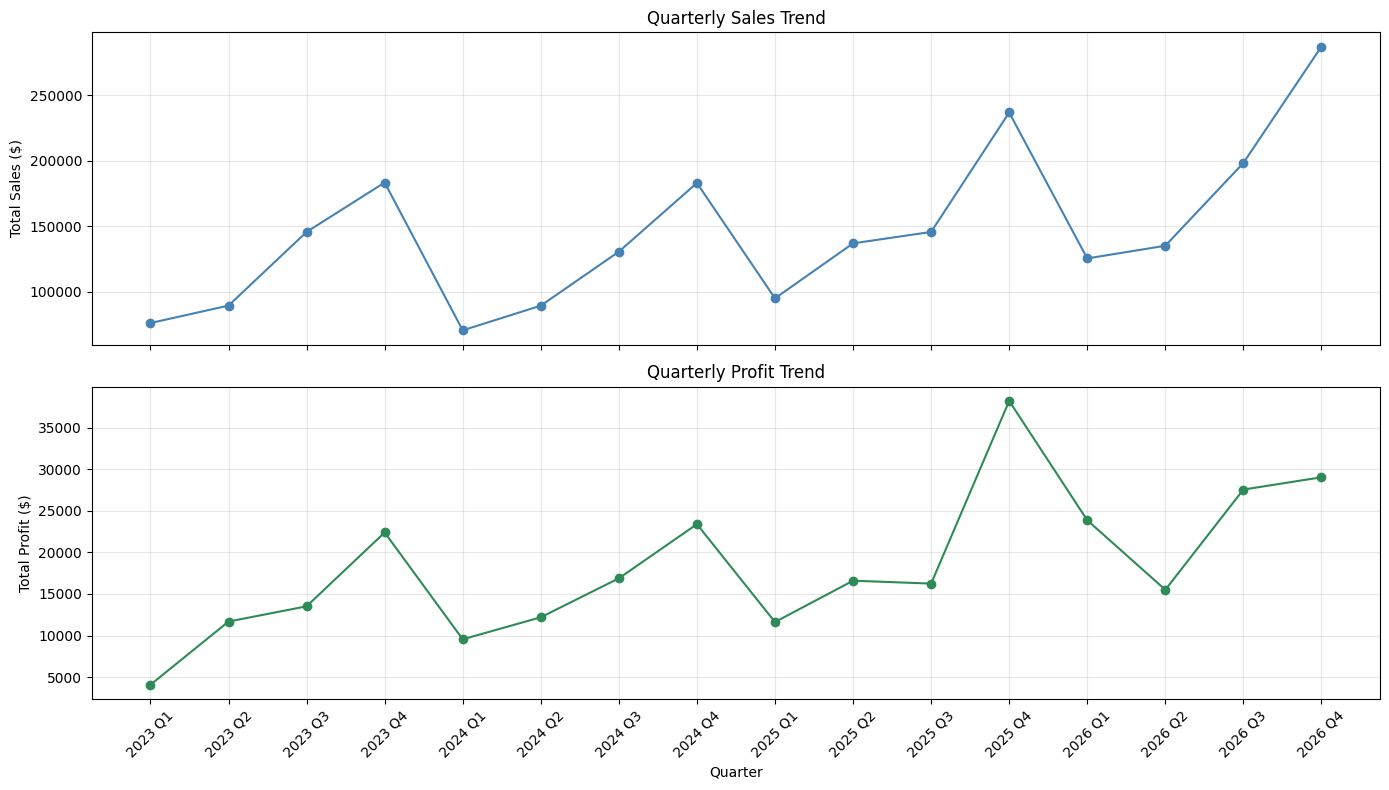

In [ ]:
quarterly_performance = quarterly_performance.sort_values(
    by=["Order Year", "Order Quarter"]
)

quarterly_performance["Quarter Label"] = (
    quarterly_performance["Order Year"].astype(str)
    + " Q"
    + quarterly_performance["Order Quarter"].astype(str)
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(
    quarterly_performance["Quarter Label"],
    quarterly_performance["Total_Sales"],
    marker="o",
    color="steelblue"
)
axes[0].set_title("Quarterly Sales Trend")
axes[0].set_ylabel("Total Sales ($)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    quarterly_performance["Quarter Label"],
    quarterly_performance["Total_Profit"],
    marker="o",
    color="seagreen"
)
axes[1].set_title("Quarterly Profit Trend")
axes[1].set_xlabel("Quarter")
axes[1].set_ylabel("Total Profit ($)")
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# calculate sales, profit, and margin across the products
product_performance = (
    orders_clean
    .groupby(
        ["Product ID", "Product Name", "Category", "Sub-Category"],
        as_index=False
    )
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

product_performance["Profit Margin"] = (
    product_performance["Total_Profit"]
    / product_performance["Total_Sales"]
)

product_performance.head(10)

,Product ID,Product Name,Category,Sub-Category,Total_Sales,Total_Profit,Profit Margin
0,FUR-BO-10000112,"Bush Birmingham Collection Bookcase, Dark Cherry",Furniture,Bookcases,825.1740,-117.8820,-0.142857
1,FUR-BO-10000330,"Sauder Camden County Barrister Bookcase, Plank...",Furniture,Bookcases,1064.6240,24.1960,0.022727
2,FUR-BO-10000362,Sauder Inglewood Library Bookcases,Furniture,Bookcases,2154.3480,311.1836,0.144444
3,FUR-BO-10000468,O'Sullivan 2-Shelf Heavy-Duty Bookcases,Furniture,Bookcases,723.8420,-133.1092,-0.183893
4,FUR-BO-10000711,"Hon Metal Bookcases, Gray",Furniture,Bookcases,851.7600,229.9752,0.270000
5,FUR-BO-10000780,O'Sullivan Plantations 2-Door Library in Landv...,Furniture,Bookcases,2946.3668,-767.7436,-0.260573
6,FUR-BO-10001337,O'Sullivan Living Dimensions 2-Shelf Bookcases,Furniture,Bookcases,2970.0590,-78.6370,-0.026477
7,FUR-BO-10001519,O'Sullivan 3-Shelf Heavy-Duty Bookcases,Furniture,Bookcases,1119.1950,147.0942,0.131429
8,FUR-BO-10001567,"Bush Westfield Collection Bookcases, Dark Cher...",Furniture,Bookcases,90.8820,-190.8522,-2.100000
9,FUR-BO-10001601,"Sauder Mission Library with Doors, Fruitwood F...",Furniture,Bookcases,935.1972,-125.7408,-0.134454


In [103]:
# Highest sales by product
product_performance.nlargest(
    10,
    "Total_Sales"
)

,Product ID,Product Name,Category,Sub-Category,Total_Sales,Total_Profit,Profit Margin
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,61599.824,2.519993e+04,4.090909e-01
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,Binders,27453.384,7.753039e+03,2.824074e-01
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.480,-1.811078e+03,-8.000000e-02
82,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,Furniture,Chairs,21870.576,3.410605e-13,1.559449e-17
701,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,Office Supplies,Binders,19823.479,2.233505e+03,1.126697e-01
667,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,Binders,19024.500,7.609800e+02,4.000000e-02
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,Technology,Copiers,18839.686,6.983884e+03,3.707006e-01
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,Technology,Machines,18374.895,4.094977e+03,2.228571e-01
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,17965.068,-1.878166e+03,-1.045455e-01
1443,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,Office Supplies,Supplies,17030.312,-2.620048e+02,-1.538462e-02


In [ ]:
# Lowest sales by product
product_performance.nsmallest(
    5,
    "Total_Sales"
)

,Product ID,Product Name,Category,Sub-Category,Total_Sales,Total_Profit,Profit Margin
427,OFF-AP-10002203,Eureka Disposable Bags for Sanitaire Vibra Gro...,Office Supplies,Appliances,1.624,-4.4660,-2.7500
1001,OFF-LA-10003388,Avery 5,Office Supplies,Labels,5.760,2.8224,0.4900
1029,OFF-PA-10000048,Xerox 20,Office Supplies,Paper,6.480,3.1104,0.4800
875,OFF-EN-10001535,Grip Seal Envelopes,Office Supplies,Envelopes,7.072,2.3868,0.3375
616,OFF-AR-10003986,Avery Hi-Liter Pen Style Six-Color Fluorescent...,Office Supplies,Art,7.700,3.1570,0.4100


In [ ]:
# highest profit by product
product_performance.nlargest(
    5,
    "Total_Profit"
)

,Product ID,Product Name,Category,Sub-Category,Total_Sales,Total_Profit,Profit Margin
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,61599.824,25199.9280,0.409091
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,Binders,27453.384,7753.0390,0.282407
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,Technology,Copiers,18839.686,6983.8836,0.370701
1637,TEC-CO-10003763,Canon PC1060 Personal Laser Copier,Technology,Copiers,11619.834,4570.9347,0.393373
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,Technology,Machines,18374.895,4094.9766,0.222857


In [ ]:
# lowest profit by product
product_performance.nsmallest(
    5,
    "Total_Profit"
)

,Product ID,Product Name,Category,Sub-Category,Total_Sales,Total_Profit,Profit Margin
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,11099.963,-8879.9704,-0.800000
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,16829.901,-4589.9730,-0.272727
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,7999.980,-3839.9904,-0.480000
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,Tables,9917.640,-2876.1156,-0.290000
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,Furniture,Tables,9544.725,-1934.3976,-0.202667


In [ ]:
# highest profit margin by product
product_performance.nlargest(
    5,
    "Profit Margin"
)

,Product ID,Product Name,Category,Sub-Category,Total_Sales,Total_Profit,Profit Margin
1002,OFF-LA-10003498,Avery 475,Office Supplies,Labels,266.40,133.20,0.5
1192,OFF-PA-10002499,Xerox 1890,Office Supplies,Paper,244.70,122.35,0.5
1270,OFF-PA-10004082,Adams Telephone Message Book w/Frequently-Call...,Office Supplies,Paper,223.44,111.72,0.5
1271,OFF-PA-10004092,Tops Green Bar Computer Printout Paper,Office Supplies,Paper,342.58,171.29,0.5
1299,OFF-PA-10004734,Southworth Structures Collection,Office Supplies,Paper,72.80,36.40,0.5


In [ ]:
# lowest profit margin by product
product_performance.nsmallest(
    5,
    "Profit Margin"
)

,Product ID,Product Name,Category,Sub-Category,Total_Sales,Total_Profit,Profit Margin
427,OFF-AP-10002203,Eureka Disposable Bags for Sanitaire Vibra Gro...,Office Supplies,Appliances,1.624,-4.4660,-2.750000
8,FUR-BO-10001567,"Bush Westfield Collection Bookcases, Dark Cher...",Furniture,Bookcases,90.882,-190.8522,-2.100000
394,OFF-AP-10000390,Euro Pro Shark Stick Mini Vacuum,Office Supplies,Appliances,170.744,-325.6332,-1.907143
1685,TEC-MA-10003337,Okidata B401 Printer,Technology,Machines,179.991,-251.9874,-1.400000
1662,TEC-MA-10001695,Zebra GK420t Direct Thermal/Thermal Transfer P...,Technology,Machines,703.710,-938.2800,-1.333333


In [ ]:
# Identify loss-making products
loss_making_products = product_performance[
    product_performance["Total_Profit"] < 0
]

loss_making_products

,Product ID,Product Name,Category,Sub-Category,Total_Sales,Total_Profit,Profit Margin
0,FUR-BO-10000112,"Bush Birmingham Collection Bookcase, Dark Cherry",Furniture,Bookcases,825.1740,-117.8820,-0.142857
3,FUR-BO-10000468,O'Sullivan 2-Shelf Heavy-Duty Bookcases,Furniture,Bookcases,723.8420,-133.1092,-0.183893
5,FUR-BO-10000780,O'Sullivan Plantations 2-Door Library in Landv...,Furniture,Bookcases,2946.3668,-767.7436,-0.260573
6,FUR-BO-10001337,O'Sullivan Living Dimensions 2-Shelf Bookcases,Furniture,Bookcases,2970.0590,-78.6370,-0.026477
8,FUR-BO-10001567,"Bush Westfield Collection Bookcases, Dark Cher...",Furniture,Bookcases,90.8820,-190.8522,-2.100000
...,...,...,...,...,...,...,...
1873,TEC-PH-10004522,Dexim XPower Skin Super-Thin Power Case for iP...,Technology,Phones,467.9200,-14.6225,-0.031250
1882,TEC-PH-10004774,Gear Head AU3700S Headset,Technology,Phones,189.6540,-11.9508,-0.063014
1884,TEC-PH-10004833,Macally Suction Cup Mount,Technology,Phones,279.6300,-31.0700,-0.111111
1885,TEC-PH-10004875,PNY Rapid USB Car Charger - Black,Technology,Phones,9.5880,-2.0774,-0.216667


In [ ]:
# Identify products with high sales but low profit margins
overall_profit_margin = total_profit / total_sales

high_sales_threshold = product_performance["Total_Sales"].quantile(0.75)

high_sales_low_margin = product_performance[
    (product_performance["Total_Sales"] >= high_sales_threshold)
    & (product_performance["Profit Margin"] < overall_profit_margin)
].sort_values(by="Total_Sales", ascending=False)

high_sales_low_margin

,Product ID,Product Name,Category,Sub-Category,Total_Sales,Total_Profit,Profit Margin
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.480,-1.811078e+03,-8.000000e-02
82,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,Furniture,Chairs,21870.576,3.410605e-13,1.559449e-17
701,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,Office Supplies,Binders,19823.479,2.233505e+03,1.126697e-01
667,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,Binders,19024.500,7.609800e+02,4.000000e-02
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,17965.068,-1.878166e+03,-1.045455e-01
...,...,...,...,...,...,...,...
1516,TEC-AC-10001314,Case Logic 2.4GHz Wireless Keyboard,Technology,Accessories,1229.754,-1.199760e+01,-9.756098e-03
1668,TEC-MA-10002210,Epson TM-T88V Direct Thermal Printer - Monochr...,Technology,Machines,1212.705,-1.057230e+03,-8.717949e-01
409,OFF-AP-10001242,APC 7 Outlet Network SurgeArrest Surge Protector,Office Supplies,Appliances,1207.200,8.048000e+01,6.666667e-02
243,FUR-FU-10002918,Eldon ClusterMat Chair Mat with Cordless Antis...,Furniture,Furnishings,1200.936,-2.565636e+02,-2.136364e-01


In [ ]:
# calculate sales, profit, and margin across the categories
category_performance = (
    orders_clean
    .groupby("Category", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
)

category_performance["Profit Margin"] = (
    category_performance["Total_Profit"]
    / category_performance["Total_Sales"]
)

category_performance.sort_values(
    by="Total_Profit",
    ascending=False
)

,Category,Total_Sales,Total_Profit,Total_Quantity,Profit Margin
2,Technology,839893.2790,146543.3756,7017,0.174479
1,Office Supplies,731893.3140,126023.4434,23268,0.172188
0,Furniture,754747.7613,19729.9956,8369,0.026141


In [ ]:
# calculate sales, profit and margin across the sub-categories
subcategory_performance = (
    orders_clean
    .groupby(["Category", "Sub-Category"], as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
)

subcategory_performance["Profit Margin"] = (
    subcategory_performance["Total_Profit"]
    / subcategory_performance["Total_Sales"]
)

subcategory_performance.sort_values(
    by="Total_Profit",
    ascending=False
)

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Profit Margin
14,Technology,Copiers,150745.2900,56093.9365,242,0.372111
16,Technology,Phones,331842.6400,45050.8265,3357,0.135760
13,Technology,Accessories,167380.3180,41936.6357,2976,0.250547
10,Office Supplies,Paper,79540.5380,34511.5070,5207,0.433886
6,Office Supplies,Binders,207354.8810,31426.1003,6071,0.151557
1,Furniture,Chairs,335768.2490,27223.5323,2431,0.081078
11,Office Supplies,Storage,224644.5540,21285.1115,3191,0.094750
4,Office Supplies,Appliances,108213.1850,18329.4844,1750,0.169383
2,Furniture,Furnishings,95598.1260,13891.7430,3799,0.145314
7,Office Supplies,Envelopes,16528.3620,6988.0247,914,0.422790


In [ ]:
# Lowest profit by subcategory
subcategory_performance.nsmallest(
    5,
    "Total_Profit"
)

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Profit Margin
3,Furniture,Tables,208020.1820,-17753.2061,1261,-0.085344
0,Furniture,Bookcases,115361.2043,-3632.0736,878,-0.031484
12,Office Supplies,Supplies,46725.4980,-1171.3945,653,-0.025070
8,Office Supplies,Fasteners,8532.2400,2428.6358,980,0.284642
15,Technology,Machines,189925.0310,3461.9769,442,0.018228


In [ ]:
# calculate sales, profit, margin, and average discount for each category and sort by average discount in descending order
category_discount_performance = (
    orders_clean
    .groupby("Category", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Discount=("Discount", "mean")
    )
)

category_discount_performance["Profit Margin"] = (
    category_discount_performance["Total_Profit"]
    / category_discount_performance["Total_Sales"]
)

category_discount_performance.sort_values(
    by="Average_Discount",
    ascending=False
)

,Category,Total_Sales,Total_Profit,Average_Discount,Profit Margin
0,Furniture,754747.7613,19729.9956,0.172962,0.026141
1,Office Supplies,731893.3140,126023.4434,0.156348,0.172188
2,Technology,839893.2790,146543.3756,0.131475,0.174479


In [ ]:
# calculate sales, profit, , margin, and average discount for each product and sort by average discount in descending order
product_discount_performance = (
    orders_clean
    .groupby(["Product ID", "Product Name", "Category"], as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Discount=("Discount", "mean")
    )
)

product_discount_performance["Profit Margin"] = (
    product_discount_performance["Total_Profit"]
    / product_discount_performance["Total_Sales"]
)

product_discount_performance.sort_values(
    by="Average_Discount",
    ascending=False
).head(10)

,Product ID,Product Name,Category,Total_Sales,Total_Profit,Average_Discount,Profit Margin
427,OFF-AP-10002203,Eureka Disposable Bags for Sanitaire Vibra Gro...,Office Supplies,1.624,-4.4660,0.800000,-2.750000
775,OFF-BI-10003166,GBC Plasticlear Binding Covers,Office Supplies,68.880,-68.4208,0.728571,-0.993333
675,OFF-BI-10000778,GBC VeloBinder Electric Binding Machine,Office Supplies,496.018,-411.3320,0.725000,-0.829268
1701,TEC-MA-10004521,Epson Perfection V600 Photo Scanner,Technology,206.991,-172.4925,0.700000,-0.833333
1695,TEC-MA-10004086,Plantronics Single Ear Headset,Technology,29.925,-21.9450,0.700000,-0.733333
1689,TEC-MA-10003589,Cisco 8961 IP Phone Charcoal,Technology,224.937,-164.9538,0.700000,-0.733333
8,FUR-BO-10001567,"Bush Westfield Collection Bookcases, Dark Cher...",Furniture,90.882,-190.8522,0.700000,-2.100000
1685,TEC-MA-10003337,Okidata B401 Printer,Technology,179.991,-251.9874,0.700000,-1.400000
1671,TEC-MA-10002694,Hewlett-Packard Deskjet F4180 All-in-One Color...,Technology,101.994,-71.3958,0.700000,-0.700000
1652,TEC-MA-10000904,"Brother MFC-9340CDW LED All-In-One Printer, Co...",Technology,341.991,-319.1916,0.700000,-0.933333


In [ ]:
# calculate the total quantity sold for each product and sort by quantity in descending order
product_quantity = (
    orders_clean
    .groupby(["Product ID", "Product Name", "Category"], as_index=False)
    .agg(
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values(by="Total_Quantity", ascending=False)
)

product_quantity.head(10)

,Product ID,Product Name,Category,Total_Quantity
228,FUR-FU-10002501,Nu-Dell Executive Frame,Furniture,84
717,OFF-BI-10001718,GBC DocuBind P50 Personal Binding Machine,Office Supplies,72
704,OFF-BI-10001524,GBC Premium Transparent Covers with Diagonal L...,Office Supplies,67
95,FUR-CH-10002647,"Situations Contoured Folding Chairs, 4/Set",Furniture,64
1744,TEC-PH-10001300,iKross Bluetooth Portable Keyboard + Cell Phon...,Technology,64
333,FUR-TA-10001095,Chromcraft Round Conference Tables,Furniture,61
209,FUR-FU-10001979,Dana Halogen Swing-Arm Architect Lamp,Furniture,60
848,OFF-BI-10004728,Wilson Jones Turn Tabs Binder Tool for Ring Bi...,Office Supplies,59
112,FUR-CH-10003774,"Global Wood Trimmed Manager's Task Chair, Khaki",Furniture,59
123,FUR-CH-10004287,SAFCO Arco Folding Chair,Furniture,59


In [ ]:
# Lowest quantity sold by product
product_quantity.nsmallest(
    10,
    "Total_Quantity"
)

,Product ID,Product Name,Category,Total_Quantity
1688,TEC-MA-10003493,Penpower WorldCard Pro Card Scanner,Technology,1
88,FUR-CH-10002317,Global Enterprise Series Seating Low-Back Swiv...,Furniture,1
1029,OFF-PA-10000048,Xerox 20,Office Supplies,1
568,OFF-AR-10002704,Boston 1900 Electric Pencil Sharpener,Office Supplies,1
17,FUR-BO-10002206,"Bush Saratoga Collection 5-Shelf Bookcase, Han...",Furniture,1
240,FUR-FU-10002874,Ultra Commercial Grade Dual Valve Door Closer,Furniture,2
427,OFF-AP-10002203,Eureka Disposable Bags for Sanitaire Vibra Gro...,Office Supplies,2
906,OFF-EN-10004206,Multimedia Mailers,Office Supplies,2
616,OFF-AR-10003986,Avery Hi-Liter Pen Style Six-Color Fluorescent...,Office Supplies,2
338,FUR-TA-10001691,Barricks Non-Folding Utility Table with Steel ...,Furniture,2


In [ ]:
# Calculate sales, profit, and margin across the discount bands
discount_band_performance = (
    orders_clean
    .groupby("Discount Band", as_index=False, observed=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
)

discount_band_performance["Profit Margin"] = (
    discount_band_performance["Total_Profit"]
    / discount_band_performance["Total_Sales"]
)

discount_band_performance

,Discount Band,Total_Sales,Total_Profit,Total_Quantity,Profit Margin
0,No Discount,1.105324e+06,326718.5872,18770,0.295586
1,Low (1–10%),5.495250e+04,9099.9700,377,0.165597
2,Medium (11–20%),8.014979e+05,92498.9432,14054,0.115408
3,High (21%+),3.647601e+05,-136020.6858,5453,-0.372904


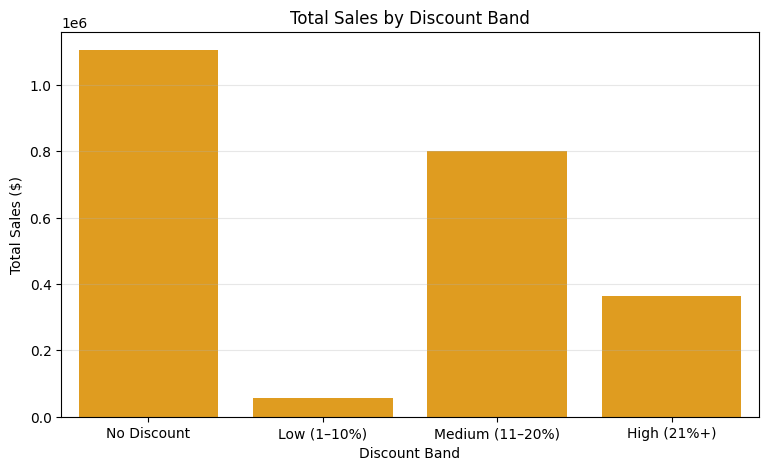

In [ ]:
# create a bar plot for total sales by discount band
plt.figure(figsize=(9, 5))

sns.barplot(
    data=discount_band_performance,
    x="Discount Band",
    y="Total_Sales",
    color="orange"
)

plt.title("Total Sales by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Total Sales ($)")
plt.grid(axis="y", alpha=0.3)

plt.show()

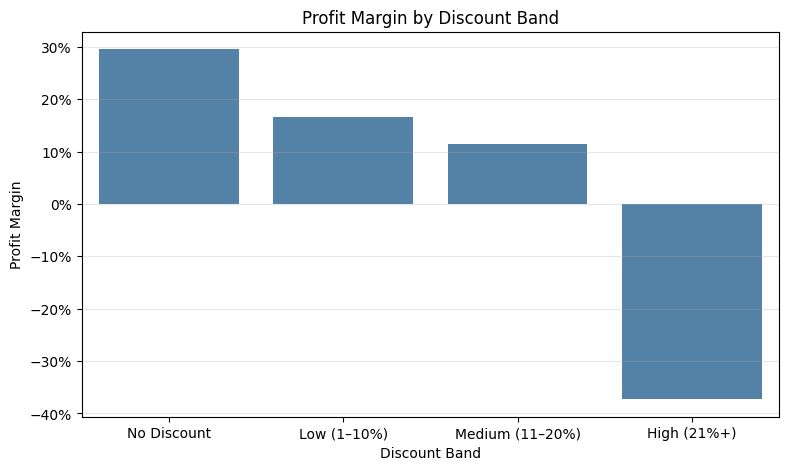

In [ ]:
# create a bar plot for profit margin by discount band
from matplotlib.ticker import PercentFormatter

plt.figure(figsize=(9, 5))

sns.barplot(
    data=discount_band_performance,
    x="Discount Band",
    y="Profit Margin",
    color="steelblue"
)

plt.title("Profit Margin by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Profit Margin")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
# Identify products with high average discounts but low profit margins. (rule: Average Discount > 20% and Profit Margin < Overall Profit Margin)
excessively_discounted_products = (
    product_discount_performance[
        (product_discount_performance["Average_Discount"] > 0.20)
        & (product_discount_performance["Profit Margin"] < overall_profit_margin)
    ]
    .sort_values(
        by=["Average_Discount", "Total_Sales"],
        ascending=[False, False]
    )
)

excessively_discounted_products[
    [
        "Product Name",
        "Category",
        "Total_Sales",
        "Total_Profit",
        "Average_Discount",
        "Profit Margin",
    ]
].head(10)

,Product Name,Category,Total_Sales,Total_Profit,Average_Discount,Profit Margin
427,Eureka Disposable Bags for Sanitaire Vibra Gro...,Office Supplies,1.624,-4.4660,0.800000,-2.750000
775,GBC Plasticlear Binding Covers,Office Supplies,68.880,-68.4208,0.728571,-0.993333
675,GBC VeloBinder Electric Binding Machine,Office Supplies,496.018,-411.3320,0.725000,-0.829268
1661,Lexmark MarkNet N8150 Wireless Print Server,Technology,723.510,-506.4570,0.700000,-0.700000
1662,Zebra GK420t Direct Thermal/Thermal Transfer P...,Technology,703.710,-938.2800,0.700000,-1.333333
1652,"Brother MFC-9340CDW LED All-In-One Printer, Co...",Technology,341.991,-319.1916,0.700000,-0.933333
1689,Cisco 8961 IP Phone Charcoal,Technology,224.937,-164.9538,0.700000,-0.733333
1701,Epson Perfection V600 Photo Scanner,Technology,206.991,-172.4925,0.700000,-0.833333
1685,Okidata B401 Printer,Technology,179.991,-251.9874,0.700000,-1.400000
1671,Hewlett-Packard Deskjet F4180 All-in-One Color...,Technology,101.994,-71.3958,0.700000,-0.700000


In [ ]:
# calculate sales, profit, margin, and average discount for each region and sort by average discount in descending order
region_discount_performance = (
    orders_clean
    .groupby("Region", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Discount=("Discount", "mean")
    )
)

region_discount_performance["Profit Margin"] = (
    region_discount_performance["Total_Profit"]
    / region_discount_performance["Total_Sales"]
)

region_discount_performance.sort_values(
    by="Average_Discount",
    ascending=False
)

,Region,Total_Sales,Total_Profit,Average_Discount,Profit Margin
0,Central,503170.6728,39865.3070,0.241002,0.079228
2,South,391721.9050,46749.4303,0.147253,0.119343
1,East,691828.1680,94883.2603,0.143436,0.137149
3,West,739813.6085,110798.8170,0.108946,0.149766


In [ ]:
# calculate sales, profit, margin, and total orders for each segment and sort by total profit in descending order
segment_performance = (
    orders_clean
    .groupby("Segment", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Customers=("Customer ID", "nunique")
    )
)

segment_performance["Profit Margin"] = (
    segment_performance["Total_Profit"]
    / segment_performance["Total_Sales"]
)

segment_performance.sort_values(
    by="Total_Profit",
    ascending=False
)

,Segment,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Profit Margin
0,Consumer,1.170660e+06,136371.4463,2628,416,0.116491
1,Corporate,7.158061e+05,94249.6400,1552,239,0.131669
2,Home Office,4.400684e+05,61675.7283,931,149,0.140150


In [ ]:
# highetst value customers
customer_performance = (
    orders_clean
    .groupby(
        ["Customer ID", "Customer Name", "Segment"],
        as_index=False
    )
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
)

customer_performance["Profit Margin"] = (
    customer_performance["Total_Profit"]
    / customer_performance["Total_Sales"]
)

customer_performance["Average Order Value"] = (
    customer_performance["Total_Sales"]
    / customer_performance["Total_Orders"]
)

customer_performance.nlargest(
    10,
    "Total_Sales"
)

,Customer ID,Customer Name,Segment,Total_Sales,Total_Profit,Total_Orders,Profit Margin,Average Order Value
711,SM-20320,Sean Miller,Home Office,25043.050,-1980.7393,5,-0.079093,5008.610000
752,TC-20980,Tamara Chand,Corporate,19052.218,8981.3239,5,0.471406,3810.443600
632,RB-19360,Raymond Buch,Consumer,15117.339,6976.0959,6,0.461463,2519.556500
741,TA-21385,Tom Ashbrook,Home Office,14595.620,4703.7883,4,0.322274,3648.905000
6,AB-10105,Adrian Barton,Consumer,14473.571,5444.8055,10,0.376190,1447.357100
443,KL-16645,Ken Lonsdale,Consumer,14175.229,806.8550,12,0.056920,1181.269083
680,SC-20095,Sanjit Chand,Consumer,14142.334,5757.4119,9,0.407105,1571.370444
328,HL-15040,Hunter Lopez,Consumer,12873.298,5622.4292,6,0.436751,2145.549667
694,SE-20110,Sanjit Engle,Consumer,12209.438,2650.6769,11,0.217101,1109.948909
132,CC-12370,Christopher Conant,Consumer,12129.072,2177.0493,5,0.179490,2425.814400


In [ ]:
# highest value customers by profit
customer_performance.nlargest(
    10,
    "Total_Profit"
)

,Customer ID,Customer Name,Segment,Total_Sales,Total_Profit,Total_Orders,Profit Margin,Average Order Value
752,TC-20980,Tamara Chand,Corporate,19052.218,8981.3239,5,0.471406,3810.443600
632,RB-19360,Raymond Buch,Consumer,15117.339,6976.0959,6,0.461463,2519.556500
680,SC-20095,Sanjit Chand,Consumer,14142.334,5757.4119,9,0.407105,1571.370444
328,HL-15040,Hunter Lopez,Consumer,12873.298,5622.4292,6,0.436751,2145.549667
6,AB-10105,Adrian Barton,Consumer,14473.571,5444.8055,10,0.376190,1447.357100
741,TA-21385,Tom Ashbrook,Home Office,14595.620,4703.7883,4,0.322274,3648.905000
161,CM-12385,Christopher Martinez,Consumer,8954.020,3899.8904,4,0.435546,2238.505000
433,KD-16495,Keith Dawkins,Corporate,8181.256,3038.6254,12,0.371413,681.771333
48,AR-10540,Andy Reiter,Consumer,6608.448,2884.6208,6,0.436505,1101.408000
235,DR-12940,Daniel Raglin,Home Office,8350.868,2869.0760,8,0.343566,1043.858500


In [ ]:
high_revenue_threshold = customer_performance["Total_Sales"].quantile(0.75)

high_revenue_low_profit_customers = (
    customer_performance[
        (customer_performance["Total_Sales"] >= high_revenue_threshold)
        & (customer_performance["Profit Margin"] < overall_profit_margin)
    ]
    .sort_values(by="Total_Sales", ascending=False)
)

high_revenue_low_profit_customers.head(10)

,Customer ID,Customer Name,Segment,Total_Sales,Total_Profit,Total_Orders,Profit Margin,Average Order Value
711,SM-20320,Sean Miller,Home Office,25043.050,-1980.7393,5,-0.079093,5008.610000
443,KL-16645,Ken Lonsdale,Consumer,14175.229,806.8550,12,0.056920,1181.269083
91,BM-11140,Becky Martin,Consumer,11789.630,-1659.9581,4,-0.140798,2947.407500
731,SV-20365,Seth Vernon,Consumer,11470.950,1199.4242,10,0.104562,1147.095000
147,CJ-12010,Caroline Jumper,Consumer,11164.974,858.7414,8,0.076914,1395.621750
393,JL-15835,John Lee,Consumer,9799.923,228.9070,11,0.023358,890.902091
311,GT-14635,Grant Thornton,Corporate,9351.212,-4108.6589,3,-0.439372,3117.070667
599,PF-19120,Peter Fuller,Consumer,9062.864,-614.2943,4,-0.067781,2265.716000
571,NF-18385,Natalie Fritzler,Consumer,8322.826,-1695.9714,7,-0.203774,1188.975143
677,SB-20290,Sean Braxton,Corporate,8057.891,-2082.7451,7,-0.258473,1151.127286


In [ ]:
# categorize customers into four groups based on their total sales and total profit
sales_median = customer_performance["Total_Sales"].median()
profit_median = customer_performance["Total_Profit"].median()

conditions = [
    (customer_performance["Total_Sales"] >= sales_median)
    & (customer_performance["Total_Profit"] >= profit_median),

    (customer_performance["Total_Sales"] >= sales_median)
    & (customer_performance["Total_Profit"] < profit_median),

    (customer_performance["Total_Sales"] < sales_median)
    & (customer_performance["Total_Profit"] >= profit_median),

    (customer_performance["Total_Sales"] < sales_median)
    & (customer_performance["Total_Profit"] < profit_median),
]

groups = [
    "High Revenue / High Profit",
    "High Revenue / Low Profit",
    "Low Revenue / High Profit",
    "Low Revenue / Low Profit",
]

customer_performance["Customer Group"] = np.select(
    conditions,
    groups,
      default="Unclassified"
)

customer_performance["Customer Group"].value_counts()

Customer Group
High Revenue / High Profit    291
Low Revenue / Low Profit      291
High Revenue / Low Profit     111
Low Revenue / High Profit     111
Name: count, dtype: int64

In [ ]:
# calculate sales, profit, margin, and total orders for each region and sort by total profit in descending order
region_performance = (
    orders_clean
    .groupby("Region", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Customers=("Customer ID", "nunique"),
        Average_Discount=("Discount", "mean")
    )
)

region_performance["Profit Margin"] = (
    region_performance["Total_Profit"]
    / region_performance["Total_Sales"]
)

region_performance.sort_values(
    by="Total_Profit",
    ascending=False
)

,Region,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Average_Discount,Profit Margin
3,West,739813.6085,110798.8170,1635,686,0.108946,0.149766
1,East,691828.1680,94883.2603,1475,685,0.143436,0.137149
2,South,391721.9050,46749.4303,822,512,0.147253,0.119343
0,Central,503170.6728,39865.3070,1179,629,0.241002,0.079228


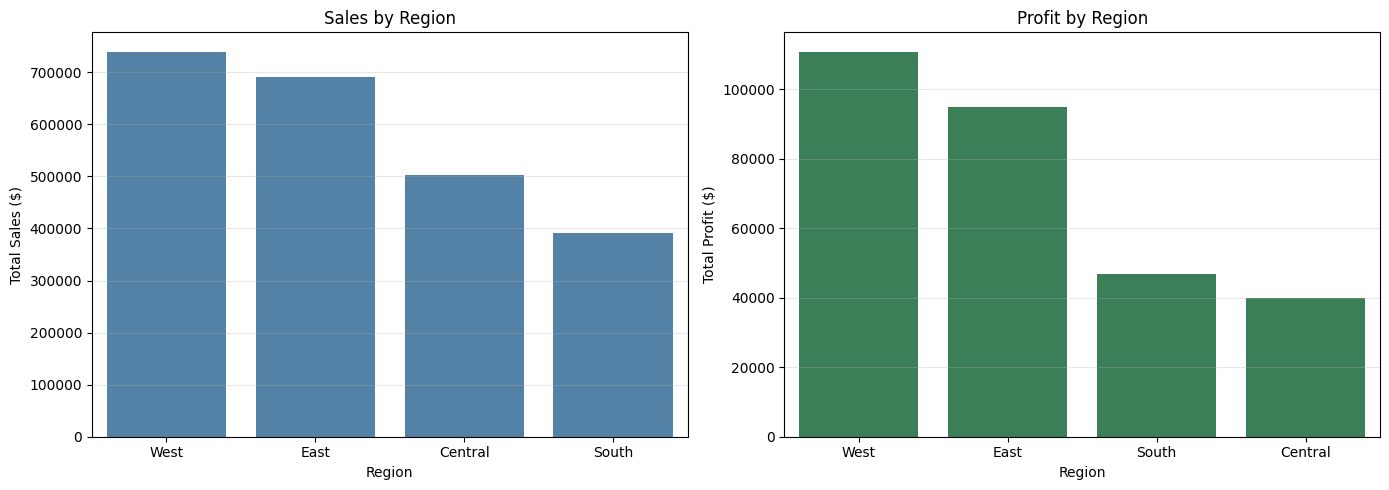

In [ ]:
# create bar plots for total sales and total profit by region
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sales_order = (
    region_performance
    .sort_values("Total_Sales", ascending=False)["Region"]
)

profit_order = (
    region_performance
    .sort_values("Total_Profit", ascending=False)["Region"]
)

sns.barplot(
    data=region_performance,
    x="Region",
    y="Total_Sales",
    order=sales_order,
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Sales by Region")
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Total Sales ($)")
axes[0].grid(axis="y", alpha=0.3)

sns.barplot(
    data=region_performance,
    x="Region",
    y="Total_Profit",
    order=profit_order,
    ax=axes[1],
    color="seagreen"
)
axes[1].set_title("Profit by Region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Total Profit ($)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Lowest profit margin by region
region_performance.sort_values(
    by="Profit Margin",
    ascending=True
)

,Region,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Average_Discount,Profit Margin
0,Central,503170.6728,39865.3070,1179,629,0.241002,0.079228
2,South,391721.9050,46749.4303,822,512,0.147253,0.119343
1,East,691828.1680,94883.2603,1475,685,0.143436,0.137149
3,West,739813.6085,110798.8170,1635,686,0.108946,0.149766


In [ ]:
# Lowest average discount by region
region_performance.sort_values(
    by="Average_Discount",
    ascending=False
)

,Region,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Average_Discount,Profit Margin
0,Central,503170.6728,39865.3070,1179,629,0.241002,0.079228
2,South,391721.9050,46749.4303,822,512,0.147253,0.119343
1,East,691828.1680,94883.2603,1475,685,0.143436,0.137149
3,West,739813.6085,110798.8170,1635,686,0.108946,0.149766


In [ ]:
# calculate sales, profit, and margin for each region and category combination
region_category_performance = (
    orders_clean
    .groupby(["Region", "Category"], as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

region_category_performance["Profit Margin"] = (
    region_category_performance["Total_Profit"]
    / region_category_performance["Total_Sales"]
)

region_category_performance.sort_values(
    by=["Region", "Total_Profit"],
    ascending=[True, False]
)

,Region,Category,Total_Sales,Total_Profit,Profit Margin
2,Central,Technology,170416.3120,33697.4320,0.197736
1,Central,Office Supplies,168216.7090,8970.0817,0.053325
0,Central,Furniture,164537.6518,-2802.2067,-0.017031
5,East,Technology,267938.0710,48441.7758,0.180795
4,East,Office Supplies,211658.4010,42996.7397,0.203142
3,East,Furniture,212231.6960,3444.7448,0.016231
8,South,Technology,148771.9080,19991.8314,0.134379
7,South,Office Supplies,125651.3130,19986.3928,0.159062
6,South,Furniture,117298.6840,6771.2061,0.057726
10,West,Office Supplies,226366.8910,54070.2292,0.238861


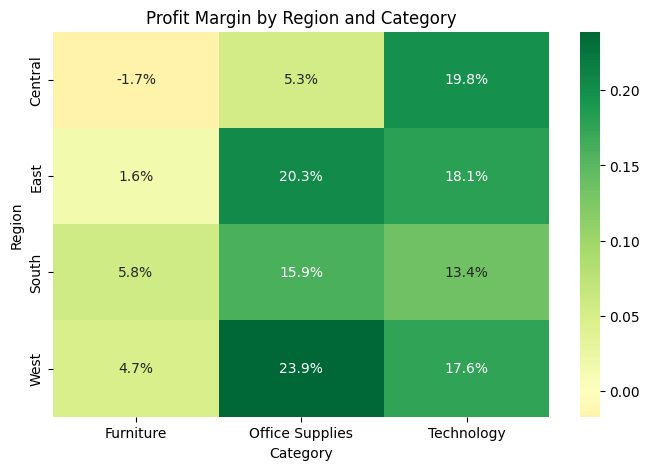

In [ ]:
# create a heatmap for profit margin by region and category
region_category_margin = region_category_performance.pivot(
    index="Region",
    columns="Category",
    values="Profit Margin"
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    region_category_margin,
    annot=True,
    fmt=".1%",
    cmap="RdYlGn",
    center=0
)

plt.title("Profit Margin by Region and Category")
plt.xlabel("Category")
plt.ylabel("Region")

plt.show()

## Key Findings

1. Overall performance

- The business generated $2.33M in sales and $292.3K in profit, achieving an overall profit margin of 12.56%. While the business is profitable, sales growth does not consistently translate into higher profitability.

- Sales peaked in November 2026, while profit peaked in December 2025, showing that higher revenue can be associated with lower-margin sales or an unfavourable product mix. January 2024 was the weakest month, recording a $3.2K loss.

 - The data also indicates a recurring Q1 decline in sales and profit from 2024 to 2026, suggesting a seasonal slowdown after strong Q4 performance. In Q2 2026, sales increased by 7.7% but profit fell by 35.0%, causing margin to decline from 19.0% to 11.5%. This indicates a separate profitability issue that should be investigated through discount, product, and category analysis.

 - Management should focus on protecting profit margins, particularly during seasonal Q1 slowdowns and periods where sales increase without a corresponding increase in profit.


2. Product performance

- Technology is the strongest category, generating the highest sales ($839.9K) and profit ($146.5K), with a 17.4% profit margin. Office Supplies also performs well, delivering a 17.2% margin and the highest sales quantity.

- Furniture is the main profitability concern. Despite generating $754.7K in sales, it achieved only a 2.6% profit margin. This weak performance is driven primarily by loss-making Tables and Bookcases. Tables generated $208.0K in sales but lost $17.8K, while Bookcases lost $3.6K.

- Profitability also varies substantially at product level. The Canon imageCLASS 2200 Copier is the most profitable product, generating $25.2K profit at a 40.9% margin. However, several high-sales products are loss-making or generate minimal profit, including Cubify CubeX 3D Printers, Lexmark Printers, Cisco TelePresence Systems, GBC DocuBind P400, and HON Task Chairs.

- Overall, the business should promote high-margin Technology and Office Supplies products while reviewing prices, discounts, and costs for loss-making Furniture and Technology products. Sales volume should not be used alone to measure product success; profit margin must remain a key decision metric.

3. Discount analysis

- "Discount band performance"
- Profitability declines substantially as discount levels increase. No-discount sales achieved a 29.6% profit margin, while high-discount sales generated a $136.0K loss and a -37.3% margin. The business should limit discounts above 20% and apply lower discounts selectively to protect profit margins.

- Furniture receives the highest average discount and has the lowest profit margin, indicating that discounting may be contributing to its weak profitability. Technology has the lowest average discount and the strongest margin, while Office Supplies remains profitable despite moderate discounting. Furniture discount policies should be reviewed first.

- Central has the highest average discount at 24.1% and the lowest regional profit margin at 7.9%. In contrast, West has the lowest average discount at 10.9% and the strongest margin at 15.0%. This supports the finding that heavy discounting is associated with weaker profitability. Management should prioritise a review of Central’s discount policy, particularly for loss-making products and categories. Discount approvals above 20% should be restricted unless they meet a clear minimum-profit-margin requirement.

- Products with average discounts of 70–80% consistently generate severe negative profit margins. Although many have low sales volume, they demonstrate that excessive discounting can make individual transactions unprofitable. Management should introduce product-level discount limits and minimum-margin approval rules.


4. Customer analysis

- Consumer is the largest customer segment by sales and profit, but it has the lowest profit margin at 11.6%. Home Office is the smallest segment but delivers the strongest margin at 14.0%. Management should protect Consumer margins through product-mix and discount review while pursuing profitable growth in Home Office.

- Several high-revenue customers are unprofitable, demonstrating that customer sales value does not always translate into customer profit. Grant Thornton and Sean Miller are priority cases because they generated substantial sales while making large losses. Management should apply customer-level margin controls and review discounts and product mix for high-revenue, low-profit accounts.

- Customer value varies significantly. Tamara Chand and Raymond Buch are high-value customers because they generate both strong sales and profit margins above 46%. However, Sean Miller generated the highest customer sales but made a loss, while Ken Lonsdale generated substantial revenue at a weak 5.7% margin. Management should assess customer performance using profit margin as well as sales and apply account-level pricing and discount controls to unprofitable accounts.

- The highest-profit customers consistently achieve margins above 32%, while the highest-sales customer is loss-making. This confirms that management should prioritise profitable customer relationships rather than ranking accounts by revenue alone.


5. Regional performance

- West is the strongest region, achieving the highest sales, profit, and profit margin while applying the lowest average discount. Central is the key regional profitability concern: it has the highest average discount and the weakest margin. Management should use West as a benchmark and prioritise stricter discount controls in Central.

- Central’s weak regional profitability is driven by loss-making Furniture and low-margin Office Supplies. Furniture is a broader business issue, producing weak margins in every region and a loss in Central. West Office Supplies is the strongest category-region combination, while Technology remains consistently profitable across all regions. Management should implement a company-wide Furniture margin strategy and prioritise stricter discount and pricing controls in Central. 

## Management Recommendations

1. Restrict discounts above 20%
High discounts generated a $136.0K loss and a -37.3% profit margin. Implement approval rules and minimum-margin controls for large discounts.

2. Fix Furniture profitability
Furniture generated $754.7K in sales but achieved only a 2.6% margin. Prioritise pricing, discount, and cost review for Tables, Bookcases, and low-margin Chairs.

3. Manage products by profit margin, not sales alone
High-sales products such as Cisco TelePresence Systems, HON Task Chairs, and GBC DocuBind P400 generate little or negative profit. Review or restrict unprofitable products and promotions.

4. Improve Central regional performance
Central has the highest average discount and the weakest profit margin. Apply stricter discount controls and focus on loss-making Furniture and low-margin Office Supplies.

5. Protect and expand profitable opportunities
Promote high-margin Technology products, profitable Office Supplies, West regional practices, high-profit customer accounts, and low-revenue/high-profit customers.

6. Plan for seasonal Q1 declines
Sales and profit decline consistently in Q1. Plan inventory and targeted margin-protected promotions before the Q1 slowdown.